# Orchestration: a single project

Runs one project through the full pipeline -- import, completion, preprocessing, calibration, reconstruction, export -- from a `ProjectConfig`, built directly or loaded from a hand-editable INI file. See [`ORCHESTRATION.md`](../ORCHESTRATION.md).

In [1]:
import sys
from pathlib import Path

here = Path.cwd()
project_root = next(p for p in [here, *here.parents] if (p / "data_import").is_dir())
sys.path.insert(0, str(project_root))

print("Using project root:", project_root)

Using project root: D:\GitHub\Universial-Reconstructions - Copy\.claude\worktrees\code-package-review-13feda


## 1. Generate sample data

Three HDF5 projects (200/300/400 projections) and two TIFF projects (200/300 projections), all the same modest phantom size so the whole notebook runs quickly. `write_hdf5()`/`write_tiff()` write in the layout `data_import/vendors/generic_parallel_synchrotron.py`'s two plugins expect.

In [2]:
from tests.fixtures.realistic_phantom import generate, write_hdf5, write_tiff

OUT = Path("generated/orchestration")
OUT.mkdir(parents=True, exist_ok=True)

SHAPE = (16, 64, 64)  # tall enough for find_tilt() to fit a reliable line across rows

# cor_deviation=1.0 keeps the offset proportionally realistic (~1.5% of
# width, matching a real detector's typical ~20px-in-1000-2000px offset)
# rather than an exaggerated one that would be easy but misleading to find.
# tilt_deg=0.0: a common, realistic case (real tilt is rarely more than
# ~1 degree, and this phantom is too small to resolve one that fine
# reliably -- see the note in section 3 below).
for n_angles in (200, 300, 400):
    phantom = generate(shape=SHAPE, n_angles=n_angles, cor_deviation=1.0, tilt_deg=0.0,
                        n_scratches=0, n_defective_pixels=0, inhomogeneity_strength=0.0,
                        noise_level=0.0, seed=n_angles)
    write_hdf5(phantom, OUT / f"scan_{n_angles}.h5")

for n_angles in (200, 300):
    phantom = generate(shape=SHAPE, n_angles=n_angles, cor_deviation=1.0, tilt_deg=0.0,
                        n_scratches=0, n_defective_pixels=0, inhomogeneity_strength=0.0,
                        noise_level=0.0, seed=n_angles)
    write_tiff(phantom, OUT / f"scan_{n_angles}_tiff")

print("Generated:", sorted(p.name for p in OUT.iterdir()))

Generated: ['scan_200.h5', 'scan_200_tiff', 'scan_300.h5', 'scan_300_tiff', 'scan_400.h5']


## 2. A single-project config file

`example_single_project.ini`, sitting alongside this notebook, points at `scan_300.h5`. Blank values mean "use the automatic behavior" -- here, auto-find both the center of rotation and the tilt.

In [3]:
print(Path("example_single_project.ini").read_text())

# Single-project orchestration config. See doc/ORCHESTRATION.md.
# Used by doc/demo/05_orchestration.ipynb, against the sample data that
# notebook generates at generated/orchestration/scan_300.h5.

[import]
path = generated/orchestration/scan_300.h5
format = hdf5
storage_mode = ram

[completion]
# generic_parallel_synchrotron_hdf5 already sets geometry_type from the
# file itself, so nothing is needed here for this particular dataset.

[preprocessing]
# rows =                # blank = every row
# zinger_removal = true
# ring_correction = true

[calibration]
center =                 # blank = auto find_center()
tilt_deg =               # blank = auto find_tilt()

[reconstruction]
backend = algotom_fbp

[postprocess]
dtype = float32
# crop = 4,8,0,96,0,96   # z0,z1,y0,y1,x0,x1

[export]
format = hdf5
path = generated/orchestration/scan_300_reconstructed.h5



## 3. Running it

`load_config()` turns the file into a `ProjectConfig`; `PipelineRun(config).run_all()` chains every stage and returns a `PipelineResult` instead of raising, so a failure (here, there isn't one) is a value to inspect, not an exception to catch.

In [4]:
from orchestration import load_config, PipelineRun

config = load_config("example_single_project.ini")
result = PipelineRun(config).run_all()

print("success:", result.success)
print("volume_path:", result.volume_path)
print("log:")
for line in result.log:
    print(" -", line)

C:\Users\a6237\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\algotom\prep\calculation.py:203: UserWarning: Global minimum is out of the searching range. Please reduce the starting value !!!
  warnings.warn(msg)


C:\Users\a6237\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\algotom\rec\reconstruction.py:422: UserWarning: !!!No Nvidia GPU found! Run with CPU instead!!!
  warnings.warn("!!!No Nvidia GPU found! Run with CPU instead!!!")


success: True
volume_path: generated\orchestration\scan_300_reconstructed.h5
log:
 - imported via generic_parallel_synchrotron_hdf5
 - completion resolved
 - preprocessed 16 rows
 - calibrated: center=32.5, tilt_deg=2.3160443251487066e-14
 - reconstructed volume (16, 64, 64)
 - postprocessed to float32, shape (16, 64, 64)
 - exported to generated\orchestration\scan_300_reconstructed.h5


The log line above shows `calibrate()` found a center close to, but not exactly, the phantom's true `cor_deviation=1.0`. That's the honest result of the tradeoff this notebook makes: keeping the COR offset at a realistic proportion of detector width (~1.5%, matching a real scan's typical offset of tens of pixels on a 1000-2000px detector) means, on a phantom kept small for a demo that runs in seconds, the true offset is under two pixels -- close to this phantom's own resolution limit. A real detector's much larger pixel count gives `find_center()` far more signal to resolve the same *proportional* offset precisely; see `test_calibration.py`'s real accuracy checks, run at a scale built for that, not for speed.

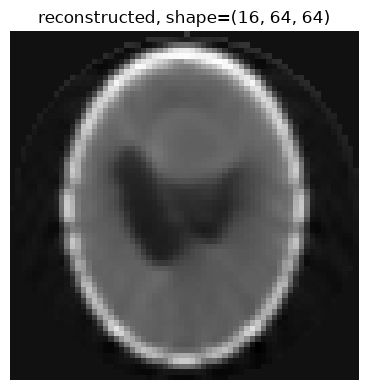

In [5]:
import h5py
import matplotlib.pyplot as plt

with h5py.File(result.volume_path, "r") as f:
    volume = f["/volume"][()]

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(volume[volume.shape[0] // 2], cmap="gray")
ax.set_title(f"reconstructed, shape={volume.shape}")
ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Inspecting the exported file's provenance

`export()` merged `project.export_metadata()` (everything resolved on the imported project: angles, voxel_size, geometry_type) with what each stage recorded (backend, center, tilt_deg) into one JSON blob, written as an HDF5 attribute on the dataset.

In [6]:
import json

with h5py.File(result.volume_path, "r") as f:
    settings = json.loads(f["/volume"].attrs["reconstruction_settings"])

for key, value in settings.items():
    display_value = value if key != "angles" else f"[{len(value)} values]"
    print(f"{key}: {display_value}")

angles: [300 values]
voxel_size: 1.0
geometry_type: parallel
center_of_rotation: 32.5
tilt_angle: 2.3160443251487066e-14
angle_span: 179.4
rotation_direction: ccw
detector_pixel_size: 1.0
center: 32.5
tilt_deg: 2.3160443251487066e-14
calibration_backend: algotom
backend: algotom_fbp


## 5. Step by step, one stage at a time

Each stage is independently callable and stores its result on the `PipelineRun` instance -- this is what a GUI actually calls, one button per stage, inspecting state (e.g. a calibration plot) before moving on. `run_all()` above is just this, chained.

In [7]:
run = PipelineRun(config)

run.import_data()
print("project:", run.project)
print("missing (soft):", run.project.missing_soft_fields())

project: ProjectObject(format=hdf5, storage_mode=ram, vendor=generic_parallel_synchrotron_hdf5, handles=['projections', 'flats', 'darks'])
missing (soft): ['angle_span', 'detector_pixel_size']


In [8]:
run.complete()
print("geometry_type:", run.project.metadata.get("geometry_type"))
print("still missing:", run.project.missing_soft_fields())

geometry_type: parallel
still missing: []


In [9]:
run.preprocess()
print("normalized shape:", run.normalized.shape)

normalized shape: (300, 16, 64)


In [10]:
run.calibrate()
print("center:", run.settings["center"])
print("tilt_deg:", run.settings["tilt_deg"])
# calibrate() writes back onto the ProjectObject too, not just run.settings:
print("project.metadata center_of_rotation:", run.project.metadata.get("center_of_rotation"))

C:\Users\a6237\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\algotom\prep\calculation.py:203: UserWarning: Global minimum is out of the searching range. Please reduce the starting value !!!
  warnings.warn(msg)


center: 32.5
tilt_deg: 2.3160443251487066e-14
project.metadata center_of_rotation: 32.5


In [11]:
run.reconstruct()
print("volume shape:", run.volume.shape, run.volume.dtype)

volume shape: (16, 64, 64) float32


C:\Users\a6237\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\algotom\rec\reconstruction.py:422: UserWarning: !!!No Nvidia GPU found! Run with CPU instead!!!
  warnings.warn("!!!No Nvidia GPU found! Run with CPU instead!!!")


In [12]:
run.postprocess()  # dtype=float32, no crop configured here -- a no-op, shown for completeness
path = run.export()
print("exported to:", path)

exported to: generated\orchestration\scan_300_reconstructed_1.h5


## 6. The same flow, on a TIFF project

No separate config file for this one -- `ProjectConfig` is a plain dataclass, so building one directly in code is just as valid as loading it from INI. `storage_mode="disk"` uses `TiffDiskHandle`: nothing is read from the TIFF folder until a stage actually asks for it.

In [13]:
from orchestration import ProjectConfig

tiff_config = ProjectConfig(
    path=str(OUT / "scan_200_tiff"), format="tiff", storage_mode="disk",
    export_format="tiff", export_path=str(OUT / "scan_200_tiff_reconstructed"),
)

tiff_result = PipelineRun(tiff_config).run_all()
print("success:", tiff_result.success, "  error:", tiff_result.error)
print("exported to:", tiff_result.volume_path)

success: True   error: None
exported to: generated\orchestration\scan_200_tiff_reconstructed


slice files: ['slice_00000.tif', 'slice_00001.tif', 'slice_00002.tif', 'slice_00003.tif', 'slice_00004.tif', 'slice_00005.tif', 'slice_00006.tif', 'slice_00007.tif', 'slice_00008.tif', 'slice_00009.tif', 'slice_00010.tif', 'slice_00011.tif', 'slice_00012.tif', 'slice_00013.tif', 'slice_00014.tif', 'slice_00015.tif']


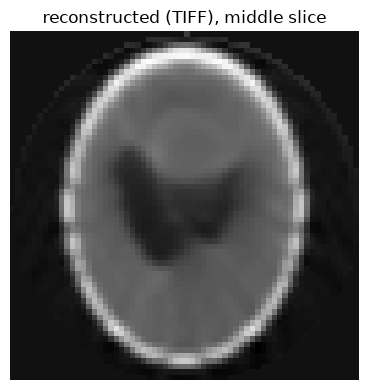

In [14]:
import tifffile

tiff_out = Path(tiff_result.volume_path)
slices = sorted(tiff_out.glob("slice_*.tif"))
print("slice files:", [s.name for s in slices])

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(tifffile.imread(slices[len(slices) // 2]), cmap="gray")
ax.set_title("reconstructed (TIFF), middle slice")
ax.axis("off")
plt.tight_layout()
plt.show()

## Recap

```
ProjectConfig (built in code, or load_config() from an INI file)
        |
        v
PipelineRun.import_data() -> .complete() -> .preprocess() -> .calibrate()
        -> .reconstruct() -> .postprocess() -> .export()
        |
        v
run_all() chains all seven, returns a PipelineResult instead of raising
```

See [`06_batch_orchestration.ipynb`](./06_batch_orchestration.ipynb) for running many projects independently from one config file, and [`ORCHESTRATION.md`](../ORCHESTRATION.md) for the full reference.